# Exploratory analysis: EU regional GDP and unemployment, 2024

Research question: are regions with higher GDP per capita in PPS associated with
lower unemployment? Run the preparation notebook first, then run this notebook
from top to bottom in a fresh kernel. No API requests are made.


## Load the analysis snapshot

Read the prepared CSV independently of the preparation notebook. Codes and flags remain text.


In [1]:
from pathlib import Path
import sys

for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / "data/metadata/acquisition_manifest.json").is_file():
        project_root = candidate
        break
else:
    raise FileNotFoundError("Run this notebook from within the project directory.")


import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

analysis_path = (
    project_root / "data" / "processed" / "regional_labour_market_2024.csv"
)

df_analysis = pd.read_csv(
    analysis_path,
    dtype={
        "region_code": "string",
        "unemployment_status": "string",
        "gdp_status": "string",
    }
)

if df_analysis.duplicated(["region_code", "year"]).any():
    raise ValueError("Duplicate region-year keys in the analysis table.")
if set(df_analysis["year"]) != {2024}:
    raise ValueError("Expected only reference year 2024.")

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print("Loaded shape:", df_analysis.shape)
print("Reference years:", df_analysis["year"].unique())


Loaded shape: (244, 7)
Reference years: [2024]


## Describe distributions and select complete pairs

Univariate summaries use available values for each indicator (244 GDP, 241 unemployment). Correlations and the scatterplot use the 241 complete pairs.


In [2]:
indicator_columns = [
    "gdp_per_capita_pps",
    "unemployment_pct",
]

descriptive_statistics = df_analysis[indicator_columns].describe()

display(descriptive_statistics.round(2))

df_complete = df_analysis.dropna(
    subset=indicator_columns
).copy()

print("Regions with both indicators:", len(df_complete))


,gdp_per_capita_pps,unemployment_pct
count,244.00,241.00
mean,37555.33,6.20
std,14251.53,4.05
min,12000.00,1.30
25%,28175.00,3.40
50%,34650.00,5.20
75%,44100.00,7.70
max,107200.00,28.30


Regions with both indicators: 241


## Inspect indicator distributions

Each region receives equal weight. Dashed and dotted lines show the mean and median. These are distributions of regional indicators, not individual outcomes.


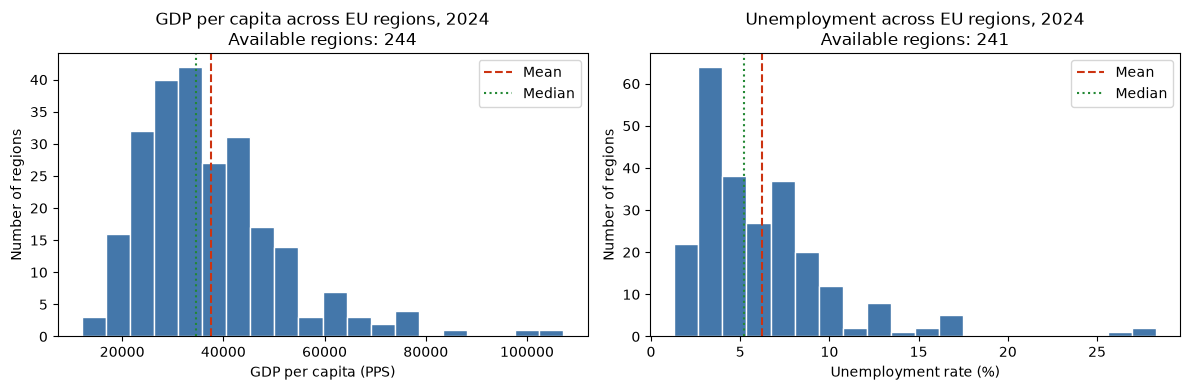

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_settings = [
    (
        "gdp_per_capita_pps",
        "GDP per capita across EU regions, 2024",
        "GDP per capita (PPS)",
    ),
    (
        "unemployment_pct",
        "Unemployment across EU regions, 2024",
        "Unemployment rate (%)",
    ),
]

for ax, (column, title, x_label) in zip(axes, plot_settings):
    values = df_analysis[column].dropna()

    ax.hist(values, bins=20, edgecolor="white", color="#4477AA")

    ax.axvline(
        values.mean(),
        color="#CC3311",
        linestyle="--",
        label="Mean",
    )
    ax.axvline(
        values.median(),
        color="#228833",
        linestyle=":",
        label="Median",
    )

    ax.set_title(f"{title}\nAvailable regions: {len(values)}")
    ax.set_xlabel(x_label)
    ax.set_ylabel("Number of regions")
    ax.legend()

fig.tight_layout()
fig.savefig(figures_dir / "indicator_distributions.png", dpi=180)
plt.show()


## Inspect the association

Each point represents one region. Keep extreme and flagged observations in the primary view. An association is not evidence of causation.


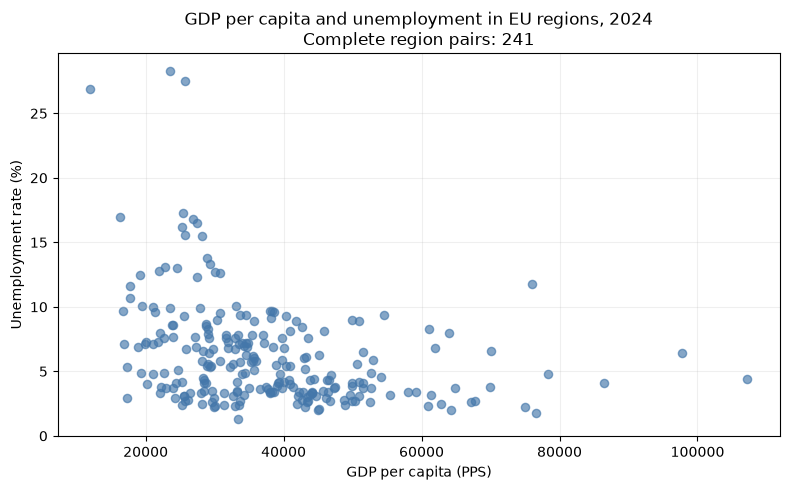

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    df_complete["gdp_per_capita_pps"],
    df_complete["unemployment_pct"],
    alpha=0.65,
    s=35,
    color="#4477AA",
)

ax.set_title(
    f"GDP per capita and unemployment in EU regions, 2024\n"
    f"Complete region pairs: {len(df_complete)}"
)
ax.set_xlabel("GDP per capita (PPS)")
ax.set_ylabel("Unemployment rate (%)")
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(figures_dir / "gdp_unemployment_scatter.png", dpi=180)
plt.show()


## Estimate the association

Primary: Spearman, calculated as Pearson correlation of average ranks. Complement: Pearson on original values. No p-values are reported: country and spatial dependence are not modelled.


In [5]:
def summarize_correlations(frame, sample_label):
    """Summarize regional GDP–unemployment correlations."""
    if frame[["gdp_per_capita_pps", "unemployment_pct"]].isna().any().any():
        raise ValueError("Correlations require complete pairs.")
    if len(frame) < 3 or frame[["gdp_per_capita_pps", "unemployment_pct"]].nunique().lt(2).any():
        raise ValueError("Correlations require at least three pairs and varying indicators.")
    gdp = frame["gdp_per_capita_pps"]
    unemployment = frame["unemployment_pct"]

    pearson_r = gdp.corr(unemployment, method="pearson")

    gdp_ranks = gdp.rank(method="average")
    unemployment_ranks = unemployment.rank(method="average")

    spearman_rho = gdp_ranks.corr(
        unemployment_ranks,
        method="pearson",
    )

    return {
        "sample": sample_label,
        "n_regions": len(frame),
        "spearman_rho": spearman_rho,
        "pearson_r": pearson_r,
    }


## Sensitivity to low-reliability unemployment observations

Exclude flags containing `u`, including combined flags such as `bdu`. GDP observations flagged `p` or `e` remain in both samples. This is a specific sensitivity check, not a claim of general robustness.


In [6]:
unemployment_u_mask = (
    df_complete["unemployment_status"]
    .str.contains("u", regex=False, na=False)
)

df_complete_without_u = df_complete.loc[
    ~unemployment_u_mask
].copy()

print("All complete pairs:", len(df_complete))
print("Complete pairs excluding u:", len(df_complete_without_u))


All complete pairs: 241
Complete pairs excluding u: 222


## Export results

Save full-precision coefficients and descriptive statistics. Displayed coefficients are rounded to three decimals. See `reports/report.md` for interpretation and limitations.


In [7]:
correlation_summary = pd.DataFrame([
    summarize_correlations(
        df_complete,
        "All complete pairs",
    ),
    summarize_correlations(
        df_complete_without_u,
        "Excluding unemployment flag u",
    ),
])

display(correlation_summary.round(3))

tables_dir = project_root / "reports" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

correlation_summary.to_csv(
    tables_dir / "correlation_summary.csv",
    index=False,
    encoding="utf-8",
)

descriptive_statistics.to_csv(
    tables_dir / "descriptive_statistics.csv",
    index_label="statistic",
    encoding="utf-8"
)


,sample,n_regions,spearman_rho,pearson_r
0,All complete pairs,241,-0.378,-0.336
1,Excluding unemployment flag u,222,-0.387,-0.338


## Interpretation

The preserved sample produces Spearman rho = −0.378 and Pearson r = −0.336
(241 regions). Excluding unemployment flag `u` gives −0.387 and −0.338
(222 regions). The overall association is negative and similar under this
specific exclusion. These cross-sectional coefficients do not establish
causation or explain individual outcomes.
